# Detector ternário de mosquitos — guia didático

Este caderno conduz o fluxo de ponta a ponta: **entender os dados → conferir o protocolo → treinar → testar em grupos separados → aplicar em um WAV**. As explicações e a execução estão reunidas aqui. Comparamos a **cascata clássica, a LSTM e a Bi-LSTM**. Módulos Python pequenos permanecem como implementação auditável das funções reutilizadas pelo treino e pela inferência.

As três saídas são `no_mosquito`, `other_mosquito` e `aedes_aegypti`. Este é um experimento offline. Os números abaixo descrevem o corpus avaliado e não demonstram confiabilidade em novas regiões, microfones ou condições de campo.

**Como acompanhar:** execute as células em ordem. Por padrão, o caderno mostra o resultado de referência sem treinar. Para iniciar um treino novo, altere `RUN_NEW_TRAINING` para `True` na célula de configuração. Para as redes, use `RUN_NEURAL_TRAINING = True`; esse controle é independente do treino clássico. Uma rodada completa pode demorar bastante e cria uma pasta nova em `results/`.

## 1. O que este experimento aprende

Cada linha da tabela corresponde a uma janela de áudio já transformada em descritores acústicos. O modelo combina regressão logística e HistGradientBoosting. O problema tem três classes: silêncio/ruído sem mosquito, outros mosquitos e *Aedes aegypti*.

A pergunta não é apenas “quantas janelas acertou?”. Janelas do mesmo arquivo se parecem. Por isso, a unidade principal do teste é o **grupo de gravação**, e blocos identificados como o mesmo áudio PCM são mantidos na mesma partição. Isso reduz vazamento entre treino e teste.

O pipeline usa validação cruzada aninhada: as dobras internas escolhem configuração e regras de decisão; a dobra externa estima desempenho em grupos que não participaram dessas escolhas. Depois do teste, um modelo final é ajustado em todos os dados de desenvolvimento para permitir a aplicação a uma gravação. Esse modelo final não tem um teste independente próprio.

Além da cascata, duas redes profundas analisam o áudio como uma sequência. A **LSTM** usa o contexto dos instantes anteriores; a **Bi-LSTM** lê o trecho nos dois sentidos. Elas recebem bandas mel, não os descritores das árvores. As três abordagens conservam a mesma tarefa e as mesmas dobras externas na comparação.

## 2. Preparar o ambiente e localizar o projeto

Na raiz do repositório, instale as dependências listadas em `requirements.txt`. Os arquivos de áudio e o cache de descritores não são copiados para o GitHub. O treino completo exige que eles estejam disponíveis localmente nos caminhos exibidos na próxima célula.

Os metadados compactos das janelas e os vínculos entre gravações acompanham o repositório em `data/metadata/`. O cache `features.npy` deve ter uma linha por janela do manifesto e ser preparado a partir dos áudios originais com o frontend descrito neste projeto.

In [1]:
from datetime import datetime, timezone
from pathlib import Path
import json
import sys

from IPython import get_ipython
_shell = get_ipython()
if _shell is not None:
    _shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

WORKING_DIR = Path.cwd().resolve()
ROOT = next((p for p in [WORKING_DIR, *WORKING_DIR.parents]
             if (p / "train_ternary_nested_models.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Abra este caderno dentro de uma cópia do projeto mosquito-wingbeat.")
sys.path.insert(0, str(ROOT))

from ternary_protocol import ROOT as PROJECT_ROOT, SEGMENTS, FEATURES, KNOWN_MAP, CLASS_NAMES
assert ROOT == PROJECT_ROOT

# Controles da execução: não sobrescrevemos rodadas anteriores.
RUN_NEW_TRAINING = False
RUN_NEURAL_TRAINING = False
VERIFY_NEURAL_RUN = False  # Reproduzir todas as previsões pode demorar.
NEURAL_DEVICE = "auto"  # "cpu", "cuda" ou escolha automática.
NEURAL_REFERENCE_RUN = ROOT / "results/ternary_verified_2026_10_14_corrections"
EXISTING_NEURAL_RUN = ROOT / "results/ternary_lstm_2026_10_15"
NEURAL_MC_PASSES = 0  # Opcional: 100 passagens, sem mudar o treino.
THREADS = 4
AUDIO_PATH = None  # Ex.: Path("/caminho/para/gravacao.wav")

print("Raiz do projeto:", ROOT)
print("Manifesto de janelas:", SEGMENTS)
print("Cache de descritores:", FEATURES)
print("Mapa de colisões PCM:", KNOWN_MAP)

Raiz do projeto: /home/lciarallo/Documentos/Git_projects/mosquito-wingbeat
Manifesto de janelas: /home/lciarallo/Documentos/Git_projects/mosquito-wingbeat/data/metadata/ternary_segments.csv.gz
Cache de descritores: /home/lciarallo/Documentos/Git_projects/mosquito-wingbeat/data/cache/reliability_2026_10_01/features.npy
Mapa de colisões PCM: /home/lciarallo/Documentos/Git_projects/mosquito-wingbeat/data/metadata/known_recording_groups.csv


## 3. Conferir as entradas antes do treino

O manifesto contém rótulos, grupo de gravação, domínio, posição temporal e índice da janela. O mapa de colisões reúne gravações que compartilham a mesma identidade PCM conhecida. O cache é uma matriz numérica alinhada linha a linha ao manifesto.

**Por que o cache não está no Git?** Ele é um artefato reconstruível e os áudios originais são volumosos. Para manter o repositório leve, o notebook interrompe o treino com uma mensagem clara se o cache local estiver ausente; os metadados necessários para interpretar/alocar as linhas continuam versionados.

In [2]:
required_inputs = {
    "manifesto de janelas": SEGMENTS,
    "cache de descritores": FEATURES,
    "mapa de colisões PCM": KNOWN_MAP,
}
missing = [f"{name}: {path}" for name, path in required_inputs.items() if not path.is_file()]
if RUN_NEW_TRAINING and missing:
    raise FileNotFoundError("Para treinar, providencie estas entradas locais:\n- " + "\n- ".join(missing))

if SEGMENTS.is_file():
    manifest = pd.read_csv(SEGMENTS, low_memory=False)
    print(f"Janelas no manifesto: {len(manifest):,}")
    display(manifest[[c for c in ["path", "label", "group", "domain", "start_s", "bucket"] if c in manifest]].head())
if FEATURES.is_file():
    feature_shape = np.load(FEATURES, mmap_mode="r").shape
    print("Formato do cache:", feature_shape)
if KNOWN_MAP.is_file():
    print("Mapa de colisões disponível:", KNOWN_MAP.stat().st_size, "bytes")

Janelas no manifesto: 49,713


,path,label,group,domain,start_s,bucket
0,data/raw/Aedes aegypti/Aedes aegypti/Auburn_T2...,Aedes aegypti,78e0631c91faf904c84f8569148778099be383553af71a...,dryad,0.0,long
1,data/raw/Aedes aegypti/Aedes aegypti/Auburn_T2...,Aedes aegypti,78e0631c91faf904c84f8569148778099be383553af71a...,dryad,1.0,long
2,data/raw/Aedes aegypti/Aedes aegypti/Auburn_T2...,Aedes aegypti,78e0631c91faf904c84f8569148778099be383553af71a...,dryad,2.0,long
3,data/raw/Aedes aegypti/Aedes aegypti/Auburn_T2...,Aedes aegypti,78e0631c91faf904c84f8569148778099be383553af71a...,dryad,3.0,long
4,data/raw/Aedes aegypti/Aedes aegypti/Auburn_T2...,Aedes aegypti,78e0631c91faf904c84f8569148778099be383553af71a...,dryad,4.0,long


Formato do cache: (49713, 138)
Mapa de colisões disponível: 176978 bytes


## 4. Um resultado de referência — sem retreino

Este retrato foi calculado a partir da avaliação OOF concluída em 14/10/2026. O caderno guarda os números essenciais para leitura e para desenhar a matriz de confusão; os milhares de arquivos intermediários da execução foram retirados do repositório.

A linha de cada classe na matriz é a classe real; a coluna é a previsão. O modelo de referência é a cascata com porta de atividade e agregação temporal. Acurácia global pode esconder erros importantes em classes menores; por isso também observamos precisão e sensibilidade de *Aedes* e falsos positivos por classe.

In [3]:
REFERENCE = {
  "run_id": "ternary_verified_2026_10_14_corrections",
  "model": "activity_gated_log_odds_cascade_event",
  "evaluation_unit": "group",
  "total_groups": 1494,
  "groups_per_class": {
    "no_mosquito": 426,
    "other_mosquito": 1008,
    "aedes_aegypti": 60
  },
  "windows_retained": 42029,
  "training_windows_by_class": {
    "no_mosquito": 8658,
    "other_mosquito": 31205,
    "aedes_aegypti": 2166
  },
  "accuracy": 0.9002677376171352,
  "balanced_accuracy": 0.8367221849616215,
  "aedes_recall": 0.7833333333333333,
  "aedes_precision": 0.6714285714285714,
  "noise_to_aedes_fpr": 0.0,
  "other_to_aedes_fpr": 0.022817460317460316,
  "noise_to_any_mosquito_fpr": 0.23943661971830985,
  "counts": {
    "aedes_tp": 47,
    "aedes_total": 60,
    "noise_fp_to_aedes": 0,
    "noise_total": 426,
    "other_fp_to_aedes": 23,
    "other_total": 1008,
    "noise_fp_to_any_mosquito": 102
  },
  "confusion_matrix": [
    [
      324,
      102,
      0
    ],
    [
      11,
      974,
      23
    ],
    [
      0,
      13,
      47
    ]
  ],
  "classes": [
    "no_mosquito",
    "other_mosquito",
    "aedes_aegypti"
  ]
}

reference_table = pd.DataFrame([
    ("Grupos avaliados (unidade principal)", REFERENCE["total_groups"]),
    ("Janelas retidas para desenvolvimento", REFERENCE["windows_retained"]),
    ("Acurácia por grupo", f"{REFERENCE['accuracy']:.1%}"),
    ("Acurácia balanceada por grupo", f"{REFERENCE['balanced_accuracy']:.1%}"),
    ("Sensibilidade de Aedes", f"{REFERENCE['aedes_recall']:.1%} ({REFERENCE['counts']['aedes_tp']}/{REFERENCE['counts']['aedes_total']})"),
    ("Precisão de Aedes", f"{REFERENCE['aedes_precision']:.1%}"),
    ("Ruído classificado como Aedes", f"{REFERENCE['counts']['noise_fp_to_aedes']}/{REFERENCE['counts']['noise_total']}"),
    ("Outros mosquitos classificados como Aedes", f"{REFERENCE['counts']['other_fp_to_aedes']}/{REFERENCE['counts']['other_total']}"),
    ("Ruído classificado como algum mosquito", f"{REFERENCE['counts']['noise_fp_to_any_mosquito']}/{REFERENCE['counts']['noise_total']}"),
], columns=["Medida", "Resultado"])
display(reference_table)
print("Contagem de grupos por classe:", REFERENCE["groups_per_class"])

,Medida,Resultado
0,Grupos avaliados (unidade principal),1494
1,Janelas retidas para desenvolvimento,42029
2,Acurácia por grupo,90.0%
3,Acurácia balanceada por grupo,83.7%
4,Sensibilidade de Aedes,78.3% (47/60)
5,Precisão de Aedes,67.1%
6,Ruído classificado como Aedes,0/426
7,Outros mosquitos classificados como Aedes,23/1008
8,Ruído classificado como algum mosquito,102/426


Contagem de grupos por classe: {'no_mosquito': 426, 'other_mosquito': 1008, 'aedes_aegypti': 60}


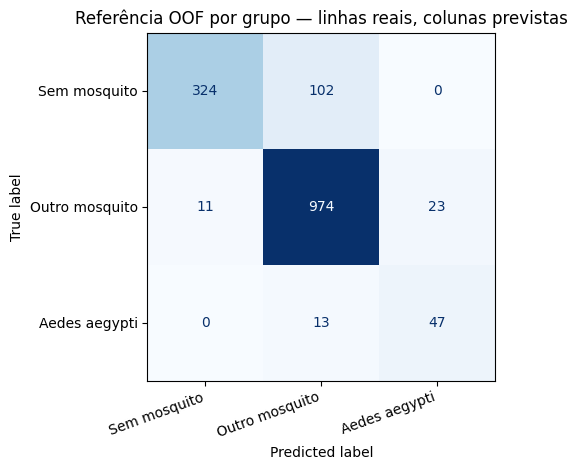

In [4]:
labels = ["Sem mosquito", "Outro mosquito", "Aedes aegypti"]
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=np.asarray(REFERENCE["confusion_matrix"]),
    display_labels=labels,
)
display_cm.plot(cmap="Blues", values_format="d", colorbar=False)
plt.title("Referência OOF por grupo — linhas reais, colunas previstas")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

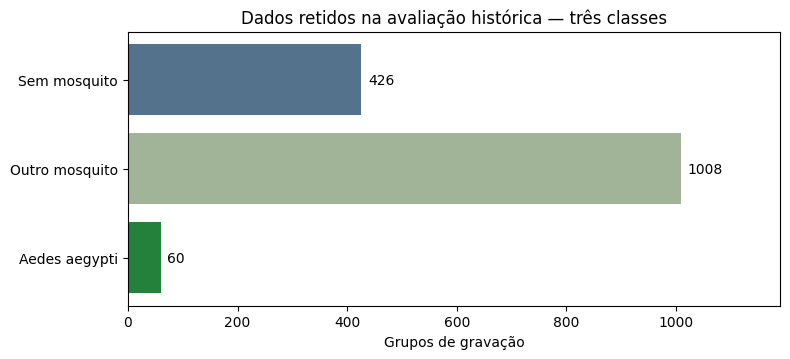

In [5]:
counts = REFERENCE["groups_per_class"]
fig, ax = plt.subplots(figsize=(8, 3.7))
values = [counts[name] for name in CLASS_NAMES]
bars = ax.barh(labels, values, color=["#54728c", "#a2b497", "#24813b"])
ax.invert_yaxis()
ax.set_xlabel("Grupos de gravação")
ax.set_title("Dados retidos na avaliação histórica — três classes")
ax.set_xlim(0, max(values) * 1.18)
for bar, value in zip(bars, values):
    ax.text(value + 12, bar.get_y() + bar.get_height()/2, str(value), va="center")
plt.tight_layout()
plt.show()

### Um exemplo real: sinal, FFT e sequência mel

Quando o cache local está disponível, esta célula usa uma janela real de Aedes do Dryad. O primeiro gráfico mostra a amplitude no tempo; a FFT mostra suas frequências; o espectrograma mel mostra a intensidade das64 bandas em55 instantes. O rótulo vem do dataset, não de uma previsão. As imagens ficam salvas no notebook executado; para recalculá-las é necessário o cache correspondente.

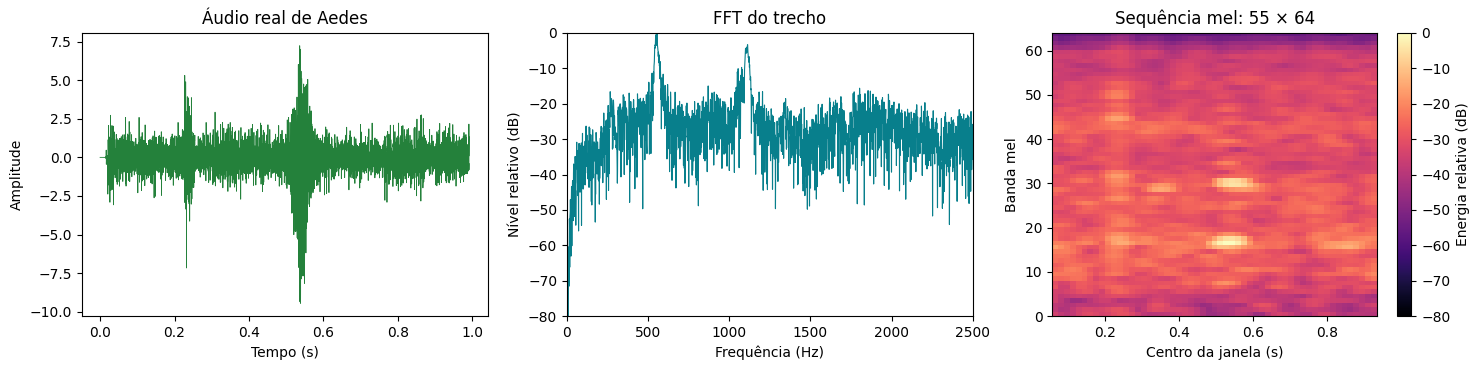

Exemplo real: data/raw/Aedes aegypti/Aedes aegypti/Auburn_T209/Voice0121 AEGY ui.wav


In [6]:
wave_cache_path = ROOT / "data/cache/reliability_2026_10_01/long_8k.npy"
if SEGMENTS.is_file() and wave_cache_path.is_file():
    import torch
    from train_ternary_lstm import frontend as neural_frontend
    examples = manifest.loc[manifest.label.eq("Aedes aegypti") & manifest.domain.eq("dryad")
                            & manifest.bucket.eq("long") & manifest.quality_ok.isin([True, "True", 1])]
    example = examples.iloc[0]
    cache = np.load(wave_cache_path, mmap_mode="r")
    wave = np.array(cache[int(example.wave_index)], dtype="float32")
    sample_rate = 8000
    seconds = np.arange(len(wave)) / sample_rate
    spectrum = np.abs(np.fft.rfft((wave - wave.mean()) * np.hanning(len(wave))))
    spectrum_db = 20 * np.log10(np.maximum(spectrum / max(spectrum.max(), 1e-12), 1e-8))
    with torch.inference_mode():
        mel = neural_frontend()(torch.from_numpy(wave[None])).numpy()[0]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    axes[0].plot(seconds, wave, color="#24813b", linewidth=.6)
    axes[0].set(title="Áudio real de Aedes", xlabel="Tempo (s)", ylabel="Amplitude")
    axes[1].plot(np.fft.rfftfreq(len(wave), 1/sample_rate), spectrum_db, color="#087f8c", linewidth=.8)
    axes[1].set(title="FFT do trecho", xlabel="Frequência (Hz)", ylabel="Nível relativo (dB)", xlim=(0, 2500), ylim=(-80, 0))
    image = axes[2].imshow(mel.T, origin="lower", aspect="auto", cmap="magma",
                           extent=[(512-64)/sample_rate, (512+128*(mel.shape[0]-1)+64)/sample_rate, 0, 64], vmin=-80, vmax=0)
    axes[2].set(title="Sequência mel: 55 × 64", xlabel="Centro da janela (s)", ylabel="Banda mel")
    fig.colorbar(image, ax=axes[2], label="Energia relativa (dB)")
    plt.tight_layout()
    plt.show()
    print("Exemplo real:", example.path)
else:
    print("Cache de áudio ausente. As demais figuras usam as referências compactas versionadas.")

## 5. Como funciona o treino e o teste

A função `train()` prepara uma rodada imutável, audita identidades de áudio, separa grupos por blocos PCM e congela os modelos antes de qualquer previsão na dobra externa. A função `evaluate()` então prevê cada grupo externo uma única vez e calcula métricas por evento/gravação.

A política principal da referência detectou 47 dos 60 grupos *Aedes* (78,3%) e não emitiu *Aedes* para os 426 grupos de ruído. Ainda classificou 23 dos 1.008 grupos de outros mosquitos como *Aedes*. A meta amostral definida para essa confusão era no máximo 19; portanto, **o critério não foi atingido**. Além disso, 102/426 grupos de ruído receberam alguma classe de mosquito.

Esses denominadores pertencem a este corpus. Grupos não são necessariamente indivíduos biológicos independentes e os intervalos binomiais não transformam essa avaliação em validação de campo.

### Iniciar uma rodada nova

O treino completo está desativado para que abrir o caderno não dispare uma execução longa. Depois de preparar os três arquivos listados na seção 3, altere `RUN_NEW_TRAINING = True` na célula de configuração e execute as células em ordem. O treino usa cinco dobras externas e quatro internas por padrão. Cada rodada recebe um nome UTC próprio e não substitui outra.

In [7]:
TRAINED_RUN = None
if RUN_NEW_TRAINING:
    from train_ternary_nested_models import train, evaluate

    run_id = datetime.now(timezone.utc).strftime("ternary_notebook_%Y%m%dT%H%M%SZ")
    TRAINED_RUN = ROOT / "results" / run_id
    train(TRAINED_RUN, threads=THREADS)
    evaluation = evaluate(TRAINED_RUN, threads=THREADS)
    print("Treino e teste concluídos em:", TRAINED_RUN)
else:
    print("Nenhum treino iniciado. A tabela e a matriz acima mostram a referência congelada.")

Nenhum treino iniciado. A tabela e a matriz acima mostram a referência congelada.


## 6. Ler os resultados da rodada nova

Ao habilitar o treino, esta célula carrega as métricas e previsões OOF recém-calculadas. A matriz mostra onde cada classe foi confundida. Examine principalmente falso positivo de *Aedes* em outros mosquitos e em ruído, além da cobertura: um sistema que se abstém muito pode apresentar boa precisão entre poucas emissões.

In [8]:
if TRAINED_RUN is not None:
    metrics_path = TRAINED_RUN / "event_level_metrics.json"
    predictions_path = TRAINED_RUN / "event_predictions.csv"
    if not metrics_path.is_file() or not predictions_path.is_file():
        raise FileNotFoundError("A etapa de avaliação não gerou os artefatos esperados.")
    fresh = json.loads(metrics_path.read_text())
    model_key = "activity_gated_log_odds_cascade_event"
    scores = fresh["models"][model_key]
    counts = scores["integer_counts"]
    display(pd.DataFrame([
        ("Execução", fresh["run_id"]),
        ("Acurácia", f"{scores['accuracy']:.1%}"),
        ("Acurácia balanceada", f"{scores['balanced_accuracy']:.1%}"),
        ("Sensibilidade Aedes", f"{counts['aedes_tp']}/{counts['aedes_total']}"),
        ("Ruído → Aedes", f"{counts['noise_fp_to_aedes']}/{counts['noise_total']}"),
        ("Outros → Aedes", f"{counts['other_fp_to_aedes']}/{counts['other_total']}"),
    ], columns=["Medida", "Resultado"]))
    event_table = pd.read_csv(predictions_path)
    matrix = pd.crosstab(event_table.true_label, event_table[model_key + "_pred"]).reindex(
        index=[0, 1, 2], columns=[0, 1, 2], fill_value=0
    ).to_numpy()
    ConfusionMatrixDisplay(matrix, display_labels=labels).plot(cmap="Blues", values_format="d", colorbar=False)
    plt.title("Rodada nova: teste OOF por grupo")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("A matriz acima corresponde à referência; ainda não houve treino nesta sessão.")

A matriz acima corresponde à referência; ainda não houve treino nesta sessão.


## 7. Aplicar o modelo a uma gravação WAV

A inferência divide o sinal em janelas reais, calcula os mesmos descritores usados no treino, verifica a integridade da rodada congelada e agrega a decisão ao nível da gravação. Trechos curtos não são repetidos nem preenchidos artificialmente.

Para aplicar o modelo criado aqui: configure `AUDIO_PATH` na seção 2, habilite e execute o treino, conclua o teste e depois rode esta célula. A saída é uma decisão experimental; não é confirmação biológica.

In [9]:
if AUDIO_PATH is None:
    print("Defina AUDIO_PATH com o caminho de um WAV para executar a inferência.")
elif TRAINED_RUN is None:
    print("Treine e teste uma rodada nesta sessão antes da aplicação; nenhum modelo binário foi publicado no repositório.")
else:
    from predict_ternary import predict_audio

    audio_path = Path(AUDIO_PATH).expanduser()
    if not audio_path.is_absolute():
        audio_path = ROOT / audio_path
    if not audio_path.is_file():
        raise FileNotFoundError(f"Gravação não encontrada: {audio_path}")
    application = predict_audio(TRAINED_RUN, audio_path)
    display(pd.Series(application, name="Resultado da aplicação").to_frame())

Defina AUDIO_PATH com o caminho de um WAV para executar a inferência.


## 8. Como a LSTM e a Bi-LSTM analisam o áudio

A rede acompanha a intensidade das frequências ao longo do tempo. A LSTM usa o que veio antes; a Bi-LSTM analisa o trecho nos dois sentidos. Ambas têm **duas camadas recorrentes, 128 unidades por direção e três saídas**. O `dropout` de20% entre camadas reduz dependências excessivas durante o treino.

**Preparação:** trecho real de0,992s a8kHz → FFT1024 com janela Hann e avanço128 → **55 instantes × 64 bandas mel** de80 a4000Hz. A normalização aprende média/desvio só no treino. A decisão por gravação combina probabilidades e dá maior peso às janelas com atividade de mosquito.

**Otimização:** Adam, taxa0,0006, lote256 e limite de gradiente3. Treina até30 épocas e para após5 sem melhora. A menor perda de validação escolhe a época. Depois, uma rede nova é ajustada no treino externo completo pelo número escolhido de épocas.

**Separação:** as redes reutilizam as cinco dobras externas por grupo/bloco PCM da cascata. Dentro de cada treino externo, uma divisão interna por grupos escolhe época e limiares. A cascata usa quatro dobras internas; a rede usa um holdout interno obtido por divisão em quatro partes. Não são protocolos internos idênticos.

São áudios reais de Dryad, HumBug e ESC-50. Os testes sintéticos e a tarefa de infecção de Torres não entram nesta comparação.

## 9. Resultados históricos das redes

Os valores abaixo foram medidos na rodada concluída em15/10/2026 e estão preservados em um JSON compacto no Git. Abrir o notebook **não recalcula o treinamento**.

Há duas regras sobre a mesma rede treinada: escolher a classe de maior probabilidade ou aplicar limiares definidos na validação. A segunda pode reduzir falsos alertas e também deixar passar mais Aedes. Acurácia geral e sensibilidade devem ser lidas juntas; as métricas de regras diferentes não devem ser misturadas.

In [10]:
NEURAL_REFERENCE_PATH = ROOT / "data/metadata/ternary_neural_reference.json"
NEURAL_REFERENCE = json.loads(NEURAL_REFERENCE_PATH.read_text())

def comparison_table(report):
    rows = [{"modelo": "Clássica", **report["reference"]}]
    for score in report["neural_models"]:
        name = "Bi-LSTM" if score["model"] == "bilstm" else "LSTM"
        rule = "maior probabilidade" if score["decision"] == "argmax" else "limiares da validação"
        rows.append({"modelo": f"{name} · {rule}", **score})
    columns = {"modelo": "Modelo e regra", "accuracy": "Acurácia", "aedes_recall": "Sensibilidade Aedes",
               "noise_to_aedes_fpr": "FPR ruído → Aedes", "other_to_aedes_fpr": "FPR outro → Aedes"}
    result = pd.DataFrame(rows)[list(columns)].rename(columns=columns)
    for column in list(columns.values())[1:]:
        result[column] = result[column].map(lambda value: f"{value:.2%}")
    return result

display(comparison_table(NEURAL_REFERENCE["metrics"]))
print("Referência histórica:", NEURAL_REFERENCE["run_id"])
print("Grupos:", NEURAL_REFERENCE["protocol_summary"]["groups"], "· janelas:", NEURAL_REFERENCE["protocol_summary"]["windows"])
print("90,03% pertence à cascata; não é a acurácia das redes.")

,Modelo e regra,Acurácia,Sensibilidade Aedes,FPR ruído → Aedes,FPR outro → Aedes
0,Clássica,90.03%,78.33%,0.00%,2.28%
1,LSTM · maior probabilidade,85.74%,86.67%,3.76%,3.97%
2,LSTM · limiares da validação,86.55%,33.33%,0.47%,0.60%
3,Bi-LSTM · maior probabilidade,82.33%,88.33%,4.93%,6.25%
4,Bi-LSTM · limiares da validação,85.27%,28.33%,0.00%,0.40%


Referência histórica: ternary_lstm_2026_10_15
Grupos: 1494 · janelas: 42029
90,03% pertence à cascata; não é a acurácia das redes.


### Acurácia e detecção de Aedes lado a lado

Cada linha representa uma regra de decisão já avaliada. Acurácia usa todos os grupos; sensibilidade usa somente os60 grupos Aedes. A mesma rede pode reduzir falsos alertas ao usar limiares e, ao mesmo tempo, deixar passar mais Aedes.

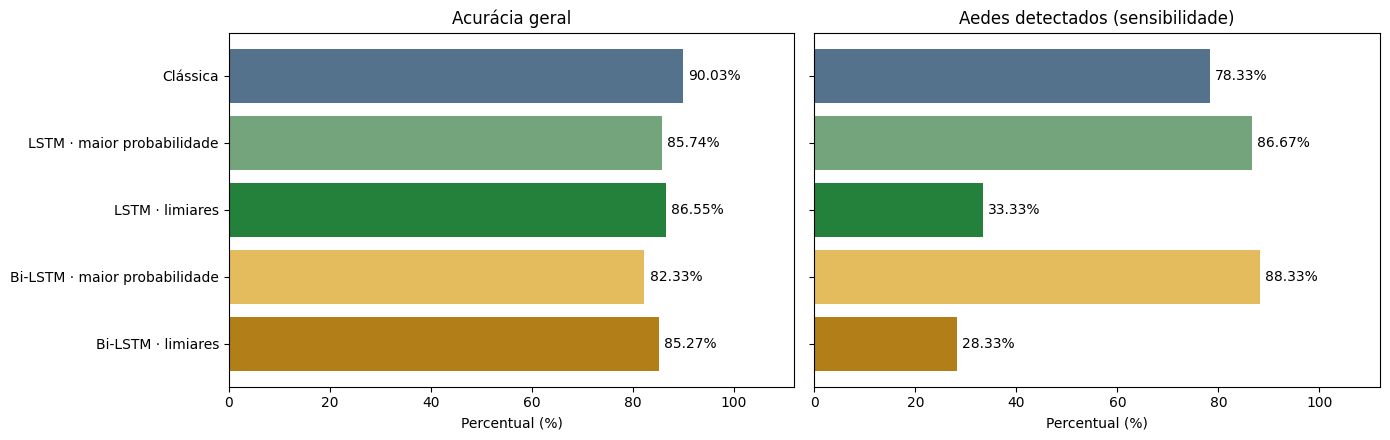

In [11]:
plot_rows = [("Clássica", NEURAL_REFERENCE["metrics"]["reference"])]
for row in NEURAL_REFERENCE["metrics"]["neural_models"]:
    name = "Bi-LSTM" if row["model"] == "bilstm" else "LSTM"
    rule = "maior probabilidade" if row["decision"] == "argmax" else "limiares"
    plot_rows.append((f"{name} · {rule}", row))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
names = [name for name, _ in plot_rows]
colors = ["#54728c", "#73a47b", "#24813b", "#e4bb5d", "#b27e17"]
for axis, key, title in zip(axes, ["accuracy", "aedes_recall"], ["Acurácia geral", "Aedes detectados (sensibilidade)"]):
    values = [100 * row[key] for _, row in plot_rows]
    bars = axis.barh(names, values, color=colors)
    axis.set(xlim=(0, 112), xlabel="Percentual (%)", title=title)
    axis.set_xticks([0, 20, 40, 60, 80, 100])
    for bar, value in zip(bars, values):
        axis.text(value + 1, bar.get_y() + bar.get_height()/2, f"{value:.2f}%", va="center")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

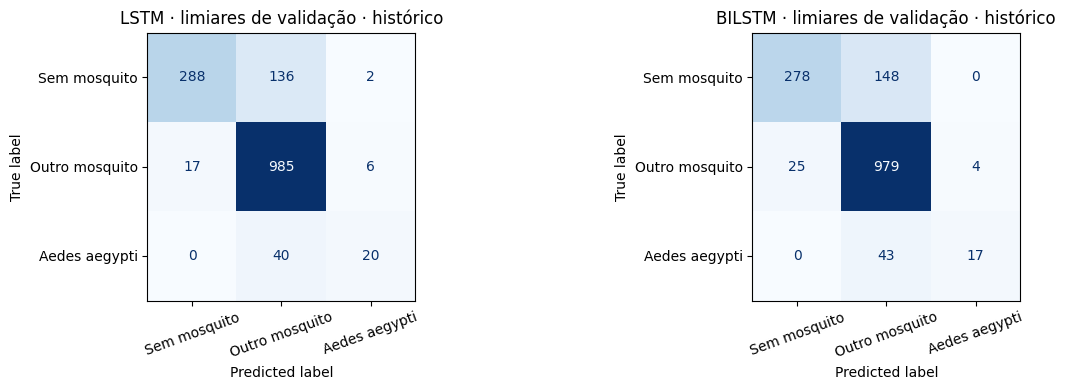

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, axis in zip(["lstm", "bilstm"], axes):
    score = next(row for row in NEURAL_REFERENCE["metrics"]["neural_models"]
                 if row["model"] == name and row["decision"] == "calibrated")
    ConfusionMatrixDisplay(np.asarray(score["confusion_matrix_raw"]), display_labels=labels).plot(
        ax=axis, cmap="Blues", values_format="d", colorbar=False)
    axis.set_title(f"{name.upper()} · limiares de validação · histórico")
    axis.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### Evolução do erro durante o treinamento

Estas são curvas reais da seleção interna do **contexto final histórico**, não médias de todas as dobras. A linha de treino mede perda por janela e a de validação mede perda por grupo; seus denominadores diferem. A linha vertical marca a época escolhida pela menor perda de validação:4 na LSTM e2 na Bi-LSTM. Não houve novo treinamento para produzir estas figuras.

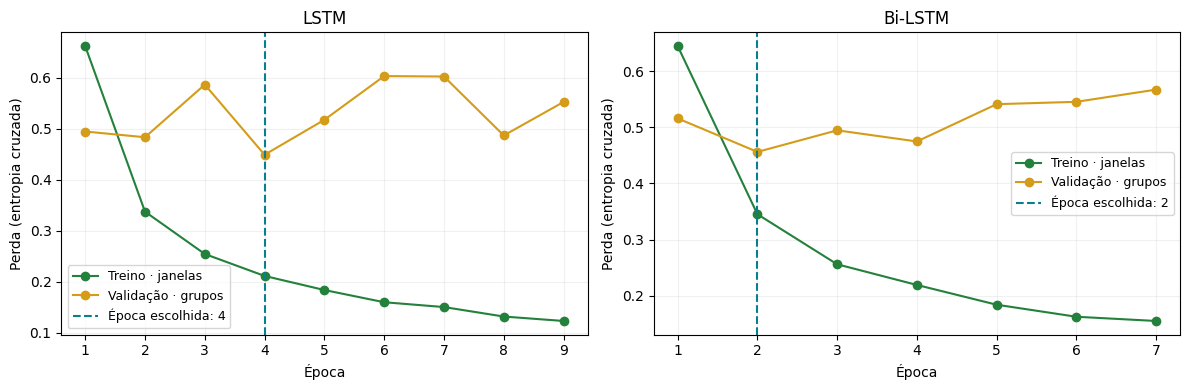

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, axis in zip(["lstm", "bilstm"], axes):
    history = pd.DataFrame(NEURAL_REFERENCE["final_training_histories"][name])
    best = next(row["best_epoch"] for row in NEURAL_REFERENCE["final_candidates"]
                if row["model"] == name)
    axis.plot(history.epoch, history.train_loss, marker="o", color="#24813b", label="Treino · janelas")
    axis.plot(history.epoch, history.validation_group_loss, marker="o", color="#d49c19", label="Validação · grupos")
    axis.axvline(best, linestyle="--", color="#087f8c", label=f"Época escolhida: {best}")
    axis.set(title="LSTM" if name == "lstm" else "Bi-LSTM", xlabel="Época", ylabel="Perda (entropia cruzada)")
    axis.set_xticks(history.epoch)
    axis.grid(alpha=.18)
    axis.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 10. Treinar LSTM e Bi-LSTM em uma nova rodada

O treino está desativado por padrão. Para executá-lo, habilite `RUN_NEURAL_TRAINING`. Se a cascata foi treinada nesta sessão, suas partições e métricas serão usadas; caso contrário, aponte `NEURAL_REFERENCE_RUN` para uma rodada clássica concluída com cinco dobras.

Entradas necessárias: `segments.csv.gz`, `partitions.csv.gz` e `event_level_metrics.json` da rodada clássica, mais `data/cache/reliability_2026_10_01/long_8k.npy`. Esse cache contém as janelas reais do manifesto, com7936 amostras por linha; índices e hashes precisam corresponder. Metadados sozinhos não substituem áudio. Os scripts de aquisição antigos não estão distribuídos neste repositório enxuto.

O programa extrai a sequência mel do cache de áudio e registra seus hashes. Uma pasta nova contém configurações, divisões, seleção interna, pesos, normalizadores e resultados das duas redes. Checkpoints históricos não são sobrescritos. Use `NEURAL_DEVICE="cpu"` se não houver PyTorch compatível com a GPU; o treino completo pode ser demorado.

In [14]:
NEURAL_RUN = None
if RUN_NEURAL_TRAINING:
    import torch
    from train_ternary_lstm import run as run_neural

    torch.set_num_threads(THREADS)
    device = torch.device(NEURAL_DEVICE if NEURAL_DEVICE != "auto"
                          else "cuda" if torch.cuda.is_available() else "cpu")
    reference_run = TRAINED_RUN if TRAINED_RUN is not None else Path(NEURAL_REFERENCE_RUN)
    if not reference_run.is_absolute():
        reference_run = ROOT / reference_run
    needed = [reference_run / name for name in
              ["segments.csv.gz", "partitions.csv.gz", "event_level_metrics.json"]]
    needed.append(ROOT / "data/cache/reliability_2026_10_01/long_8k.npy")
    missing = [str(path) for path in needed if not path.is_file()]
    if missing:
        raise FileNotFoundError("Prepare a rodada clássica e o cache de áudio antes de treinar:\n" + "\n".join(missing))
    run_id = datetime.now(timezone.utc).strftime("ternary_neural_notebook_%Y%m%dT%H%M%S%fZ")
    NEURAL_RUN = ROOT / "results" / run_id
    run_neural(NEURAL_RUN, reference_run, device)
    print("LSTM e Bi-LSTM treinadas e avaliadas em:", NEURAL_RUN)
elif EXISTING_NEURAL_RUN is not None:
    candidate = Path(EXISTING_NEURAL_RUN)
    candidate = candidate if candidate.is_absolute() else ROOT / candidate
    if (candidate / "complete.json").is_file():
        NEURAL_RUN = candidate
        print("Rodada local existente disponível, sem retreino:", NEURAL_RUN)
    else:
        print("Nenhuma rodada neural local. A comparação acima é a referência histórica publicada.")
else:
    print("Nenhum treino neural iniciado.")

Rodada local existente disponível, sem retreino: /home/lciarallo/Documentos/Git_projects/mosquito-wingbeat/results/ternary_lstm_2026_10_15


## 11. Ler os resultados de uma rodada neural local

Esta célula só mostra uma rodada efetivamente concluída. Se forem usados os pesos locais antigos, os resultados continuam sendo históricos. A verificação opcional reproduz todas as previsões OOF e confere partições, normalização, épocas e hashes; não altera os pesos nem os recibos anteriores.

In [15]:
if NEURAL_RUN is not None:
    completed = json.loads((NEURAL_RUN / "complete.json").read_text())
    if not completed.get("complete"):
        raise ValueError("A rodada neural ainda não foi concluída.")
    neural_metrics = json.loads((NEURAL_RUN / "metrics.json").read_text())
    display(comparison_table(neural_metrics))
    if VERIFY_NEURAL_RUN:
        import torch
        from verify_ternary_lstm import verify as verify_neural
        device = torch.device(NEURAL_DEVICE if NEURAL_DEVICE != "auto"
                              else "cuda" if torch.cuda.is_available() else "cpu")
        display(verify_neural(NEURAL_RUN, device))
else:
    print("Sem resultados de nova rodada. Consulte os números históricos da seção9.")

,Modelo e regra,Acurácia,Sensibilidade Aedes,FPR ruído → Aedes,FPR outro → Aedes
0,Clássica,90.03%,78.33%,0.00%,2.28%
1,LSTM · maior probabilidade,85.74%,86.67%,3.76%,3.97%
2,LSTM · limiares da validação,86.55%,33.33%,0.47%,0.60%
3,Bi-LSTM · maior probabilidade,82.33%,88.33%,4.93%,6.25%
4,Bi-LSTM · limiares da validação,85.27%,28.33%,0.00%,0.40%


## 12. Aplicar as duas redes a um WAV

Defina `AUDIO_PATH`. A rodada vem do treino acima ou de `EXISTING_NEURAL_RUN`, que exige pesos/normalizadores locais já concluídos. Um clone não baixa modelos automaticamente. Cada arquitetura usa seu próprio normalizador e limiares congelados, sem ajuste a partir desse WAV.

O trecho precisa ter pelo menos0,992s reais. A rede analisa as janelas completas; a cauda incompleta é descartada, sem repetir ou preencher o áudio. `NEURAL_MC_PASSES=100` ativa100 passagens de dropout como análise adicional de discordância; concordância não comprova acerto. A avaliação OOF principal é determinística.

In [16]:
if AUDIO_PATH is None:
    print("Defina AUDIO_PATH para aplicar LSTM e Bi-LSTM ao áudio.")
elif NEURAL_RUN is None:
    print("Configure uma rodada neural concluída ou execute o treino neural antes da aplicação.")
else:
    import torch
    from predict_ternary_lstm import predict as predict_neural
    torch.set_num_threads(THREADS)
    audio_path = Path(AUDIO_PATH).expanduser()
    audio_path = audio_path if audio_path.is_absolute() else ROOT / audio_path
    answers = []
    for architecture in ["lstm", "bilstm"]:
        answer = predict_neural(NEURAL_RUN, audio_path, name=architecture,
                                passes=NEURAL_MC_PASSES, device=NEURAL_DEVICE)
        answers.append({"Modelo": architecture.upper(), "Decisão": answer["decision"],
                        "Janelas reais": answer["windows"],
                        "Probabilidades [ruído, outro, Aedes]": answer["deterministic_probabilities"]})
    display(pd.DataFrame(answers))

Defina AUDIO_PATH para aplicar LSTM e Bi-LSTM ao áudio.


## 13. Interpretar e comunicar com responsabilidade

- `no_mosquito`: o modelo não encontrou evidência suficiente para as classes de mosquito avaliadas.
- `other_mosquito`: candidato a mosquito fora de *Aedes aegypti*; a classe agrega diferentes espécies.
- `aedes_aegypti`: candidato da classe, sujeito a falsos positivos observados no teste.
- `invalid_audio`: entrada inválida segundo as verificações de qualidade.

A avaliação é retrospectiva e limitada aos grupos e às fontes deste corpus. Os dados podem compartilhar indivíduos, locais ou condições de gravação. Uma gravação externa pequena também não substitui uma coleta independente. Antes de qualquer uso operacional, seriam necessárias novas gravações com indivíduos/sessões separados, rótulos biológicos confirmados, ruído sem mosquito e protocolo definido antes do teste.

## Arquivos de implementação usados pelo caderno

## Implementações clássicas e neurais

O notebook é o roteiro único de uso e ensino. Os módulos abaixo permanecem separados para que o congelamento por hash, as funções de treino e a inferência usem a mesma implementação auditável:

- `ternary_protocol.py`: leitura, filtragem, classes, grupos, auditoria PCM e regras temporais.
- `train_ternary_nested_models.py`: ajuste aninhado, modelos, calibração interna e congelamento.
- `evaluate_ternary_event_pipeline.py` e `ternary_reporting.py`: previsões externas e métricas por grupo.
- `predict_ternary.py`: aplicação em uma gravação nova.
- `aedes_classical.py` e `bioacoustic_invariance.py`: extração dos descritores acústicos.

O manifesto e o mapa de grupos ficam em `data/metadata/`. Áudios e cache de descritores são entradas locais e não são versionados neste repositório.

- `train_ternary_lstm.py`: treino LSTM/Bi-LSTM nas dobras clássicas, seleção interna e resultados OOF.
- `torres_lstm.py`: arquitetura recorrente e frontend mel reutilizados; o nome remete à técnica, não a um treino de infecção neste caderno.
- `predict_ternary_lstm.py`: aplicação dos pesos finais das duas redes.
- `verify_ternary_lstm.py`: reprodução das previsões e auditoria da rodada neural.
- `data/metadata/ternary_neural_reference.json`: resultados históricos compactos e hashes da origem.

Fontes de método: Torres et al. (2025), artigo fornecido para o projeto, e implementação arquivada no repositório do projeto. Os dados de infecção e o experimento de transferência posterior não foram acrescentados ao fluxo deste notebook.